# Task 22: Outlier Handling Strategies

## Objective
To handle extreme outliers using Winsorization and log transformation.
The methods are compared with the original data using descriptive
statistics and visualizations to justify the selected strategy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [2]:
numerical_df = df.select_dtypes(include=["number"])

# Exclude target because it is a class label
feature_columns = [
    col for col in numerical_df.columns
    if col != "target"
]

print("Numerical features:", feature_columns)

Numerical features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [3]:
def manual_percentile(values, percentile):
    values = sorted(
        float(value) for value in values
        if pd.notna(value)
    )

    if not values:
        return 0

    position = (len(values) - 1) * percentile / 100
    lower = int(position)
    upper = min(lower + 1, len(values) - 1)
    fraction = position - lower

    return (
        values[lower] * (1 - fraction)
        + values[upper] * fraction
    )


def manual_mean(values):
    values = [
        float(value) for value in values
        if pd.notna(value)
    ]

    return sum(values) / len(values) if values else 0


def manual_std(values):
    values = [
        float(value) for value in values
        if pd.notna(value)
    ]

    if len(values) < 2:
        return 0

    mean_value = manual_mean(values)

    variance = sum(
        (value - mean_value) ** 2 for value in values
    ) / (len(values) - 1)

    return variance ** 0.5


def manual_skewness(values):
    values = [
        float(value) for value in values
        if pd.notna(value)
    ]

    if len(values) < 3:
        return 0

    mean_value = manual_mean(values)
    std_value = manual_std(values)

    if std_value == 0:
        return 0

    third_moment = sum(
        ((value - mean_value) / std_value) ** 3
        for value in values
    ) / len(values)

    return third_moment

In [4]:
winsorized_df = df.copy()
log_transformed_df = df.copy()

for col in feature_columns:
    values = [
        float(value) for value in df[col]
        if pd.notna(value)
    ]

    if not values:
        continue

    # Winsorization: cap values at 5th and 95th percentiles
    lower_bound = manual_percentile(values, 5)
    upper_bound = manual_percentile(values, 95)

    winsorized_df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    # Log transformation
    if min(values) >= 0:
        log_transformed_df[col] = np.log1p(df[col])
    else:
        # Shift values so that the smallest value becomes zero
        shift = abs(min(values))
        log_transformed_df[col] = np.log1p(df[col] + shift)

print("Winsorization and log transformation completed.")

Winsorization and log transformation completed.


In [5]:
comparison_rows = []

for col in feature_columns:
    original = [
        float(value) for value in df[col]
        if pd.notna(value)
    ]

    winsorized = [
        float(value) for value in winsorized_df[col]
        if pd.notna(value)
    ]

    transformed = [
        float(value) for value in log_transformed_df[col]
        if pd.notna(value)
    ]

    comparison_rows.append({
        "Feature": col,
        "Original Mean": manual_mean(original),
        "Winsorized Mean": manual_mean(winsorized),
        "Log Mean": manual_mean(transformed),
        "Original Std": manual_std(original),
        "Winsorized Std": manual_std(winsorized),
        "Original Skewness": manual_skewness(original),
        "Winsorized Skewness": manual_skewness(winsorized),
        "Log Skewness": manual_skewness(transformed)
    })

comparison_df = pd.DataFrame(comparison_rows)

print(comparison_df.round(3).to_string(index=False))

 Feature  Original Mean  Winsorized Mean  Log Mean  Original Std  Winsorized Std  Original Skewness  Winsorized Skewness  Log Skewness
     age         54.434           54.449     4.001         9.072           8.514             -0.248               -0.236        -0.623
     sex          0.696            0.696     0.482         0.460           0.460             -0.849               -0.849        -0.849
      cp          0.942            0.942     0.521         1.030           1.030              0.528                0.528         0.222
trestbps        131.612          131.257     4.879        17.517          15.320              0.738                0.382         0.304
    chol        246.000          244.780     5.489        51.593          43.871              1.071                0.287         0.082
     fbs          0.149            0.149     0.103         0.357           0.357              1.966                1.966         1.966
 restecg          0.530            0.515     0.363     

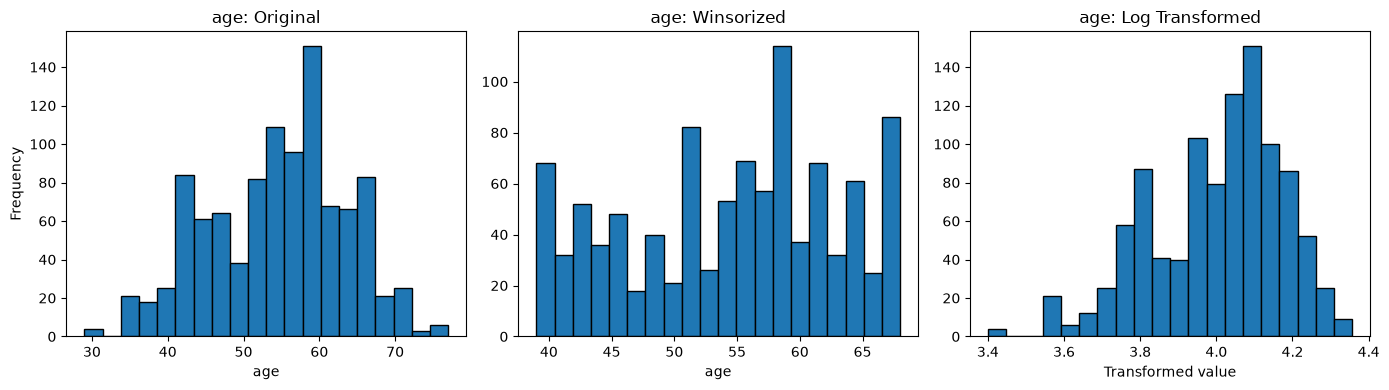

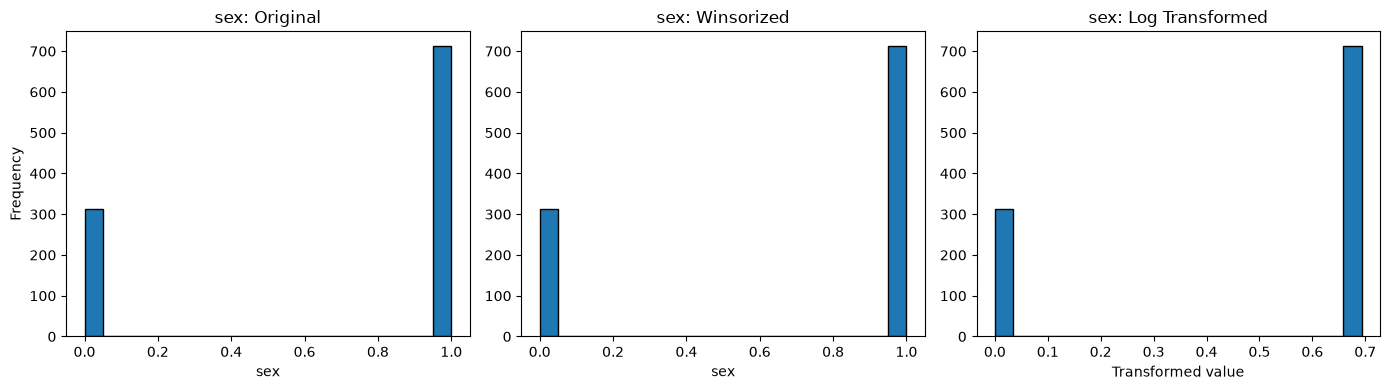

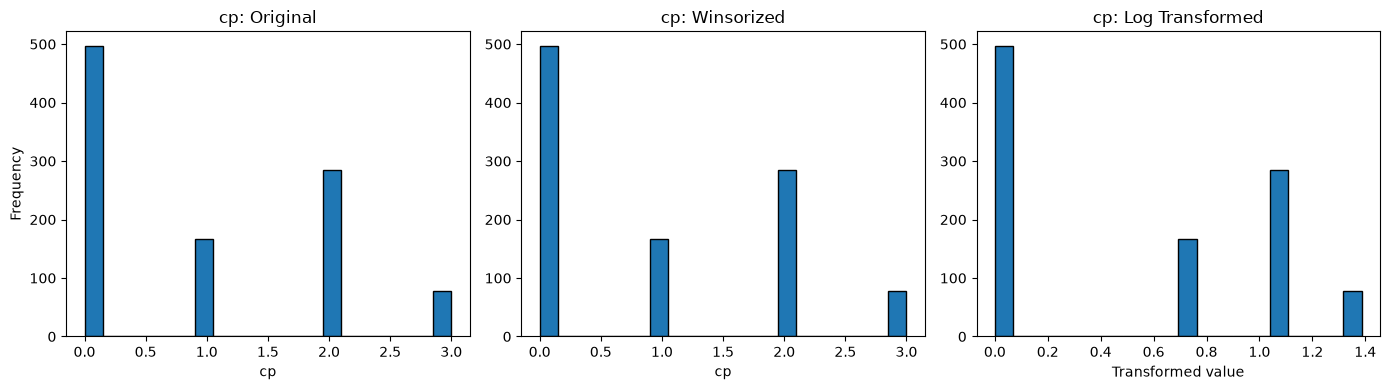

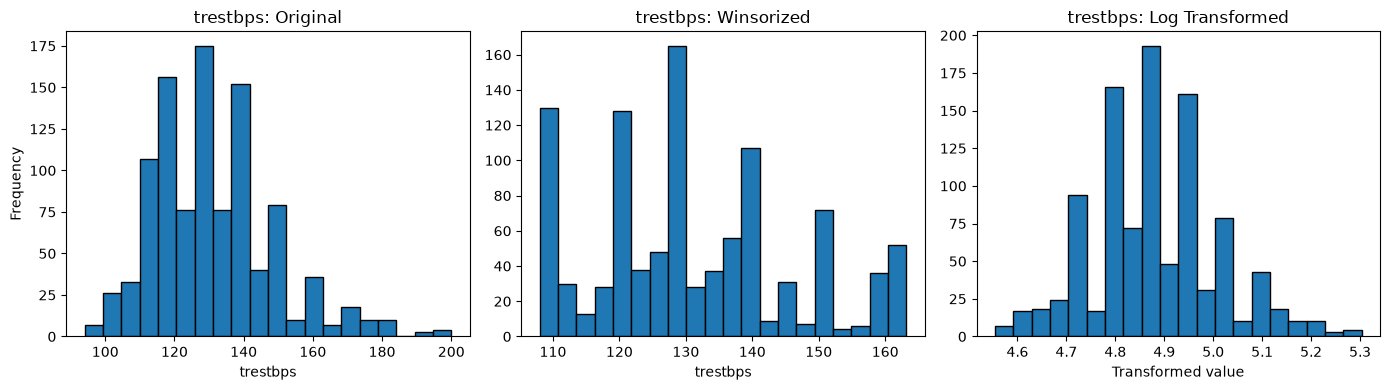

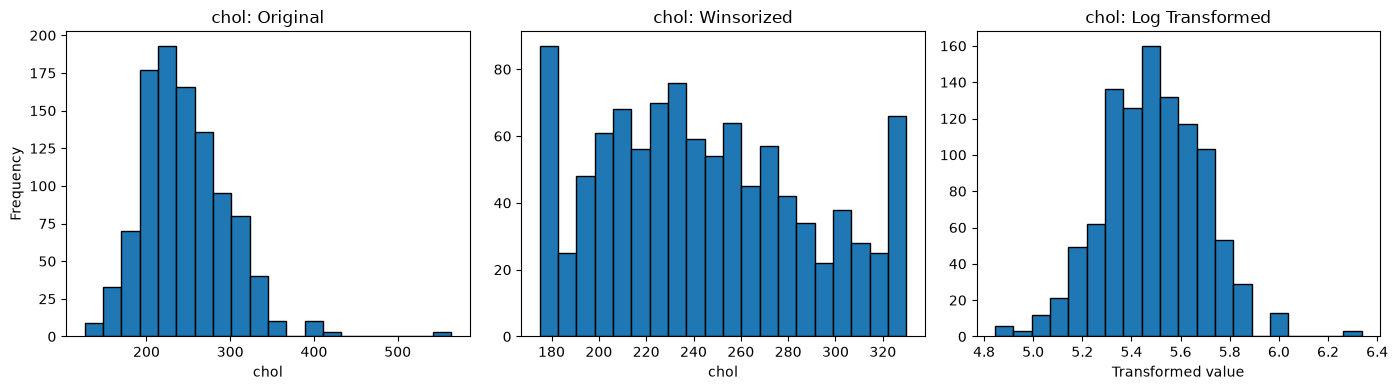

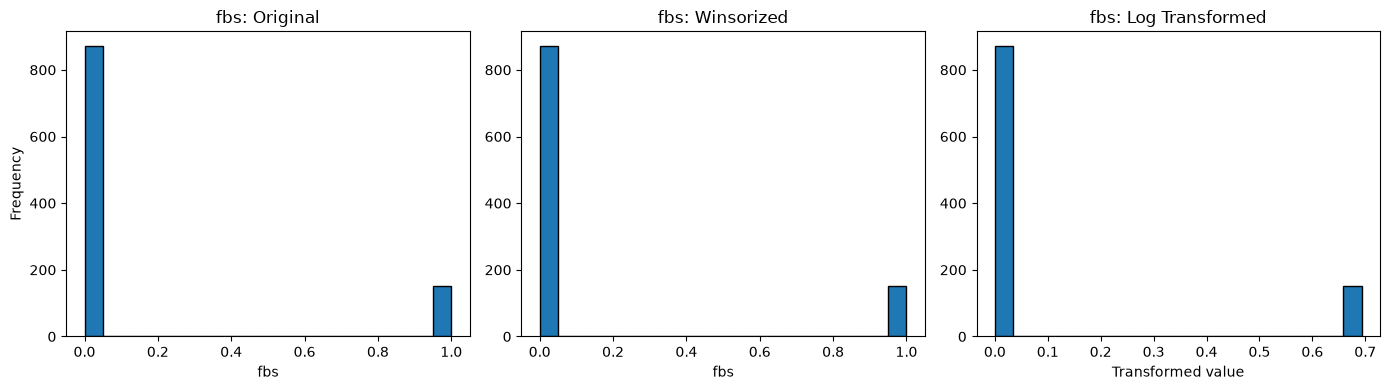

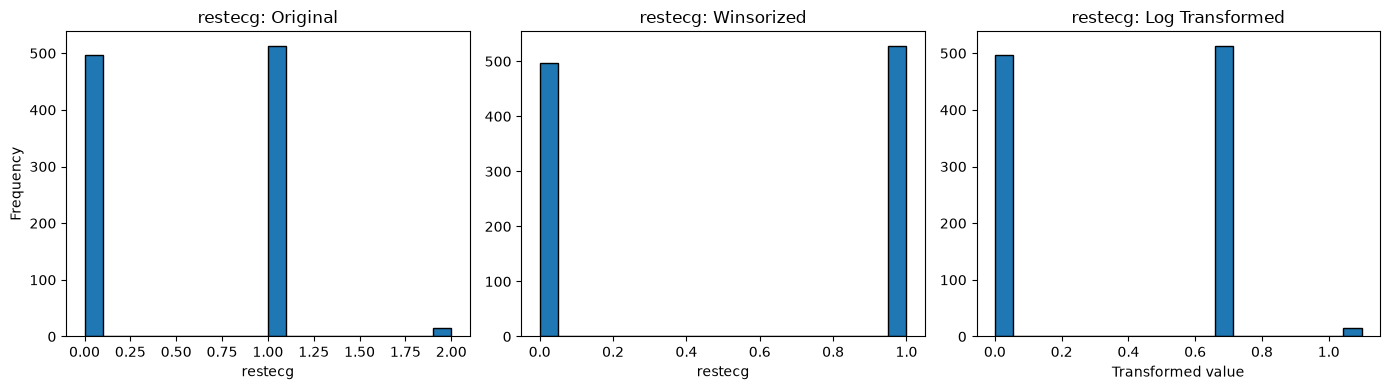

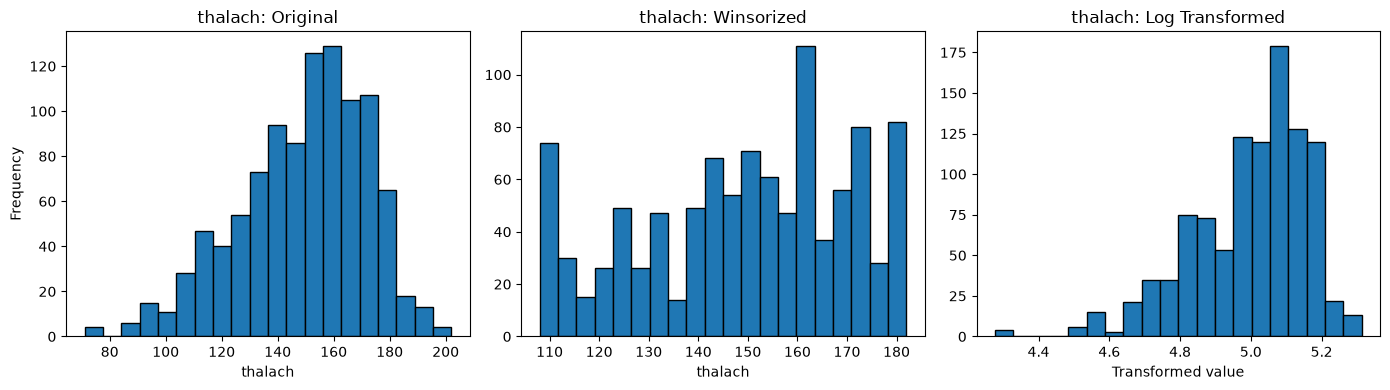

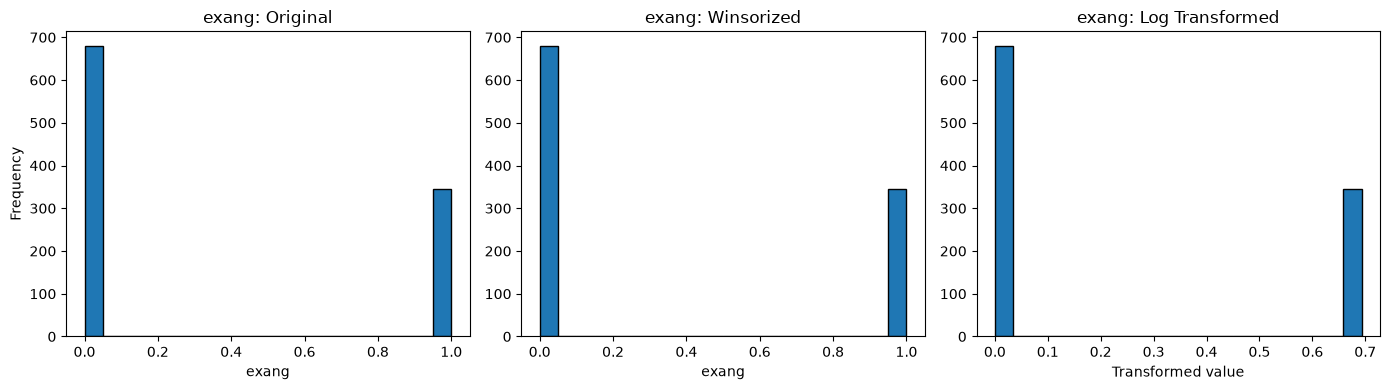

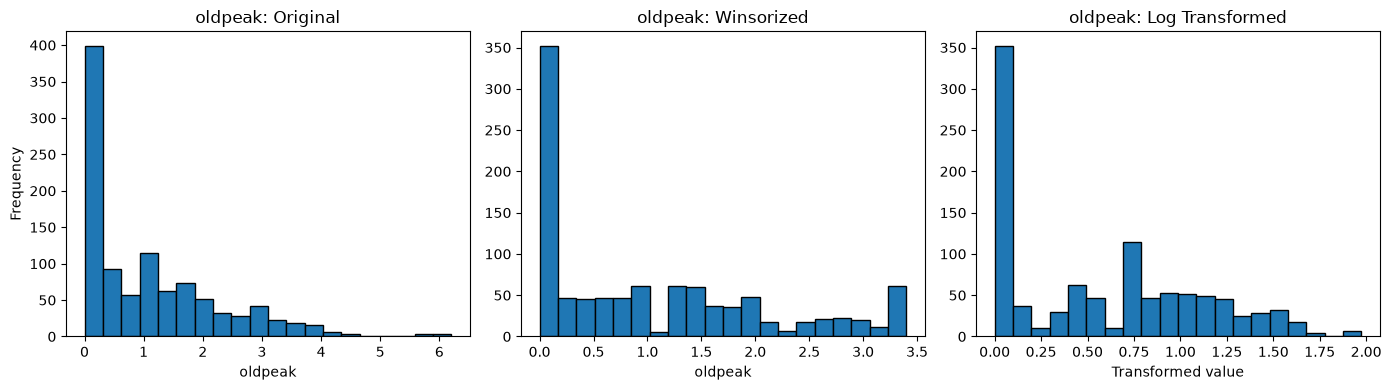

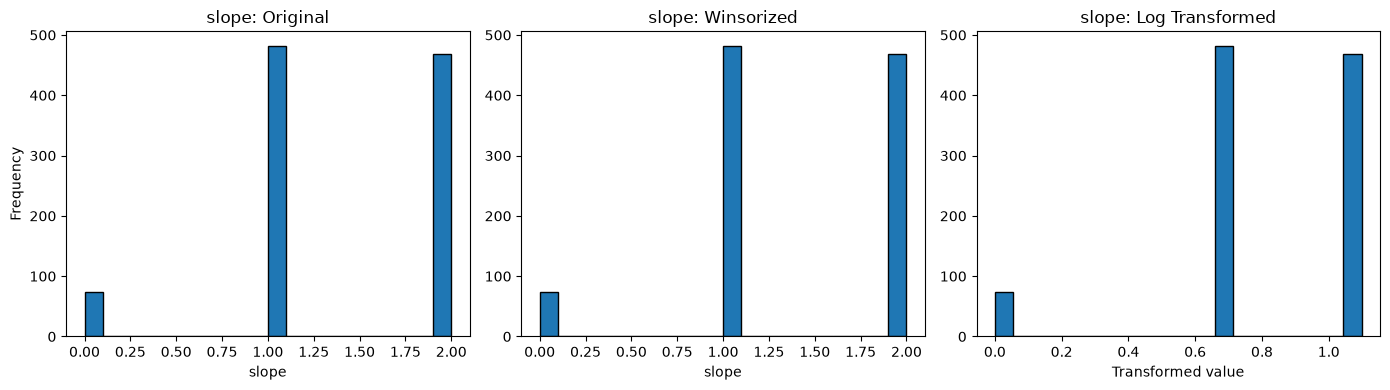

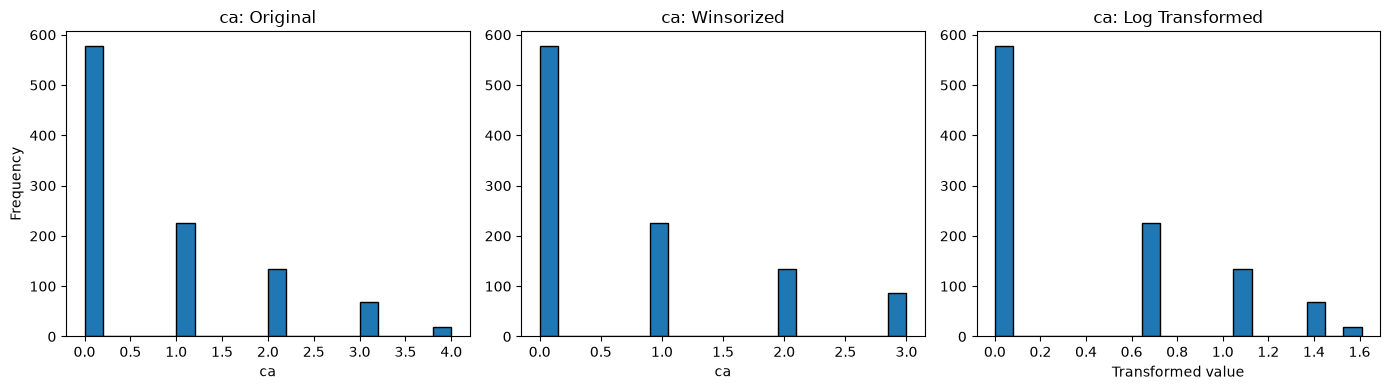

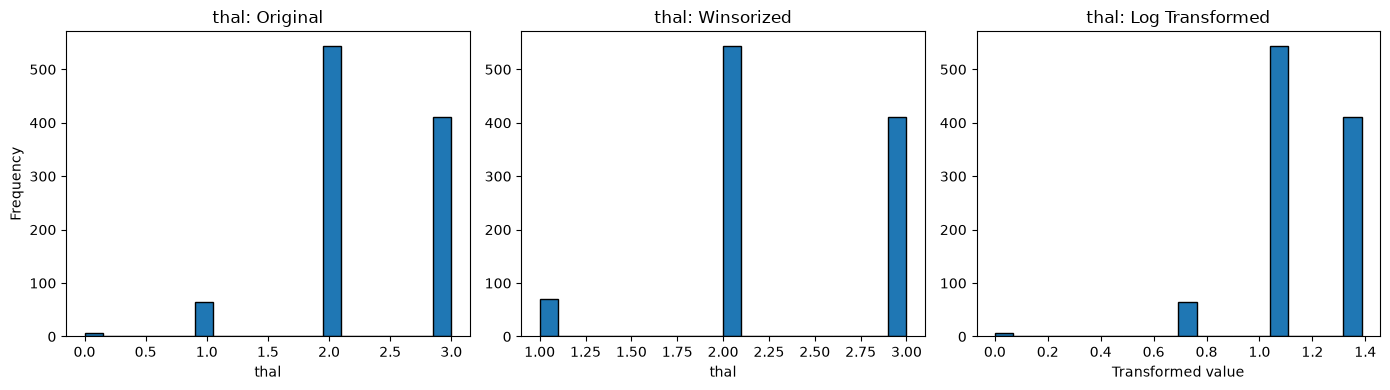

In [6]:
for col in feature_columns:
    original = df[col].dropna().tolist()
    winsorized = winsorized_df[col].dropna().tolist()
    transformed = log_transformed_df[col].dropna().tolist()

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].hist(original, bins=20, edgecolor="black")
    axes[0].set_title(f"{col}: Original")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")

    axes[1].hist(winsorized, bins=20, edgecolor="black")
    axes[1].set_title(f"{col}: Winsorized")
    axes[1].set_xlabel(col)

    axes[2].hist(transformed, bins=20, edgecolor="black")
    axes[2].set_title(f"{col}: Log Transformed")
    axes[2].set_xlabel("Transformed value")

    plt.tight_layout()
    plt.show()

In [7]:
print("Number of values changed by Winsorization:\n")

for col in feature_columns:
    changed_count = 0

    for original, adjusted in zip(df[col], winsorized_df[col]):
        if pd.notna(original) and pd.notna(adjusted):
            if original != adjusted:
                changed_count += 1

    print(f"{col}: {changed_count} values changed")

Number of values changed by Winsorization:

age: 86 values changed
sex: 0 values changed
cp: 0 values changed
trestbps: 97 values changed
chol: 94 values changed
fbs: 0 values changed
restecg: 15 values changed
thalach: 84 values changed
exang: 0 values changed
oldpeak: 51 values changed
slope: 0 values changed
ca: 18 values changed
thal: 7 values changed


## Conclusion

Winsorization and log transformation were applied to numerical features
and compared with the original data using descriptive statistics and
histograms.

Winsorization limits the influence of extreme values by capping them
at selected percentile boundaries. Log transformation changes the
scale of values and may reduce right-skewness.

The preferred method should be selected based on the observed feature
distributions and the intended modeling objective. Neither method
should be assumed superior for every feature, and transformed data
should be checked for information loss and interpretability.